# Information extraction

## Imports

In [1]:
# General
import os

# Keywords extraction
import yake

# Wordcloud
from collections import Counter
from wordcloud import WordCloud
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

# Named entities recognition
from collections import defaultdict
import spacy
from spacy.lang.fr.examples import sentences

# Sentiment analysis
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\senek\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
c:\Users\senek\OneDrive\Documents\ULB\GIT\sticb545\tac\.venv\Lib\site-packages\textblob\_text.py:218: SyntaxWarning: invalid escape sequence '\.'
  RE_ABBR1 = re.compile("^[A-Za-z]\.$")       # single letter, "T. De Smedt"
c:\Users\senek\OneDrive\Documents\ULB\GIT\sticb545\tac\.venv\Lib\site-packages\textblob\_text.py:219: SyntaxWarning: invalid escape sequence '\.'
  RE_ABBR2 = re.compile("^([A-Za-z]\.)+$")    # alternating letters, "U.S."
c:\Users\senek\OneDrive\Documents\ULB\GIT\sticb545\tac\.venv\Lib\site-packages\textblob_fr\_text.py:212: SyntaxWarning: invalid escape sequence '\.'
  RE_ABBR1 = re.compile("^[A-Za-z]\.$")       # single letter, "T. De Smedt"
c:\Users\senek\OneDrive\Documents\ULB\GIT\sticb545\tac\.venv\Lib\site-packages\textblob_fr\_text.py:213: SyntaxWarning: invalid escape sequence '\.'
  RE_ABBR2 = re.comp

## Keywords

In [2]:
# Instantiation of keywords extractor
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

# List files corresponding to the year
year = 1962
data_path = "../../data/txt/"
files = [f for f in os.listdir(data_path) if f.endswith('.txt') and str(year) in f]

# Extraction of bigrams from the files
for f in sorted(files)[:10]:
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1962-01-09_01-00012.txt mentions these keywords: New York, SOIR MARDI, lots Anvers, eeBana traité, Ford Motor, Cours Indicatifs, Congo lots, Liège 53-68, Roan Antelope, Société Générale...
KB_JB838_1962-01-09_01-00015.txt mentions these keywords: Faire offre, AGENCE ROSSEL, l'AGENCE ROSSEL, Ecrire Agence, IMPORTANTE SOCIETE, BRUXELLES demande, IMPORTANTE FIRME, FIRME IMPORTANTE, entrée Immédiate, Rossel num, FIRME BRUXELLES, EMPLOYEES DACTYLOS...
KB_JB838_1962-01-16_01-00018.txt mentions these keywords: dem. fem, Bons gages, Bruxelles Tél, Brux. dem, Bon ouvrier, Bruxelles Téléph, dem BONS...
KB_JB838_1962-01-21_01-00027.txt mentions these keywords: RIP KIRBY, Agence Rossel, beau magasin, Ecrire Agence, JOHN PRENTICE, GROS PRIX, Cse santé, Charlerol Tél...
KB_JB838_1962-01-21_01-00030.txt mentions these keywords: OPEL REKORD, vapeur d’eau, DERNIERE EDITION, EDITION PARUE, Opel Kapltan, moteur chaud, moteur utilisé, changement notable, nuit Dem...
KB_JB838_1962-01-25_01-00009.t

## Wordcloud

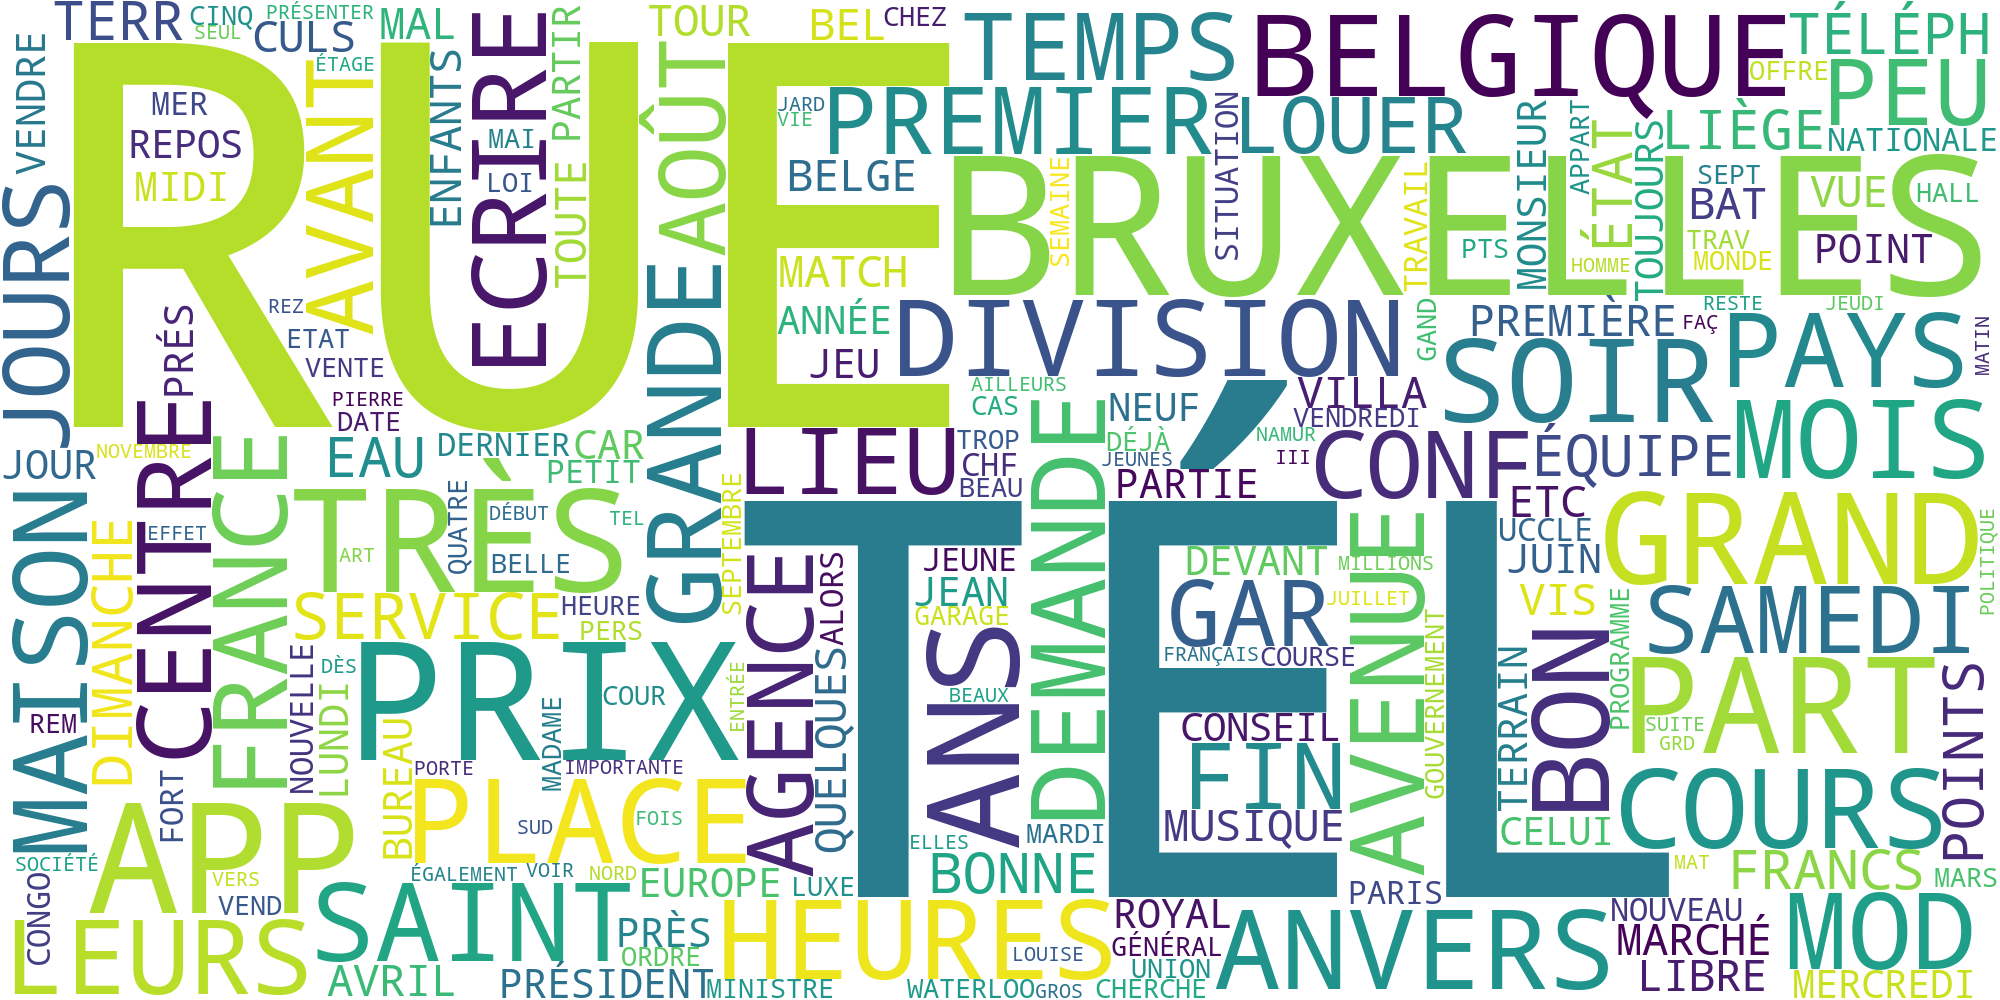

In [10]:
# Stopwords
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem", "brux", "ecr"]
sw = set(sw)

# Choisir une année
year = 1962

# List files corresponding to the year
data_path = '../../data'
txt_path = '../../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]

# Store the content of txts in a list
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

# Write the content in a temporary file
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

# Function that cleans the file from stopwords and other noise
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

# Execute the cleaning function
clean_text(year, folder=temp_path)

# Import the cleaned file 
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

# Calculate the most frequent terms
frequencies = Counter(after.split())

# Generate, store and display the wordcloud
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))

## Named entities recognition

In [22]:
%%time

# Loading the model
nlp = spacy.load('fr_core_news_md')

n = 1000000
text = open(f"../../data/tmp/{year}_clean.txt", encoding='utf-8').read()[:n]

# Traiter le texte
doc = nlp(text)

# Compter les entités
people = defaultdict(int)
organisations = defaultdict(int)
locations = defaultdict(int)

for ent in doc.ents:
    if ent.label_ == "PER" and len(ent.text) > 3:
        people[ent.text] += 1
    elif ent.label_ == "ORG" and len(ent.text) > 3:
        organisations[ent.text] += 1
    elif ent.label_ == "LOC" and len(ent.text) > 3:
        locations[ent.text] += 1

# Trier et imprimer

sorted_people = sorted(people.items(), key=lambda kv: kv[1], reverse=True)
sorted_organisations = sorted(organisations.items(), key=lambda kv: kv[1], reverse=True)
sorted_locations = sorted(locations.items(), key=lambda kv: kv[1], reverse=True)

def print_entities(entity):
    for ent, freq in entity[:50]:
         print(f"{ent} apparait {freq} fois dans le corpus")


CPU times: total: 44.1 s
Wall time: 44.7 s


In [23]:
print_entities(sorted_people)

ÉLEVÉS apparait 3 fois dans le corpus
LOUIS BELGE apparait 3 fois dans le corpus
AUVELALS apparait 2 fois dans le corpus
LINGERIE BONNETER apparait 2 fois dans le corpus
AYRES apparait 2 fois dans le corpus
PHÉNIX WORKS apparait 2 fois dans le corpus
JOHN KENNEDY apparait 2 fois dans le corpus
CERTAINE apparait 2 fois dans le corpus
RAY GRASS apparait 2 fois dans le corpus
TIRLEMONT apparait 2 fois dans le corpus
JEAN XXIII apparait 2 fois dans le corpus
LOUIS LOUIS XVI apparait 2 fois dans le corpus
CERTAINE MESURE apparait 1 fois dans le corpus
VLCTN VICTN apparait 1 fois dans le corpus
SAMB MEURA apparait 1 fois dans le corpus
BELREF BÈMST apparait 1 fois dans le corpus
MERB SPR MERB apparait 1 fois dans le corpus
SOUVERNIN ANCIEN apparait 1 fois dans le corpus
NAPOLÉON GAGNE apparait 1 fois dans le corpus
LOUIS BEIGE apparait 1 fois dans le corpus
LIQUEURS apparait 1 fois dans le corpus
AVANTAGEA EXTRA apparait 1 fois dans le corpus
MEUNERIE PRÉSENTER RUE apparait 1 fois dans le co

In [24]:
print_entities(sorted_organisations)

GAND apparait 50 fois dans le corpus
OPEL apparait 41 fois dans le corpus
AVRIL apparait 38 fois dans le corpus
EUROPE apparait 27 fois dans le corpus
PART apparait 26 fois dans le corpus
ANTWERPSE apparait 26 fois dans le corpus
RENS apparait 23 fois dans le corpus
AGENCE apparait 22 fois dans le corpus
ANDERLECHT apparait 20 fois dans le corpus
FIAT apparait 18 fois dans le corpus
OUVR apparait 17 fois dans le corpus
SUETENS apparait 16 fois dans le corpus
CONGO apparait 14 fois dans le corpus
LÉOPOLD apparait 14 fois dans le corpus
ALLEMAGNE apparait 13 fois dans le corpus
FOLS apparait 13 fois dans le corpus
FIRME apparait 13 fois dans le corpus
PEUGEOT apparait 11 fois dans le corpus
PAYS apparait 11 fois dans le corpus
AUTOMOBILE apparait 11 fois dans le corpus
MAZOUT apparait 11 fois dans le corpus
TERMINA apparait 11 fois dans le corpus
ROBERT apparait 11 fois dans le corpus
AUTOS apparait 11 fois dans le corpus
DOLLAR apparait 10 fois dans le corpus
DÉSIRE apparait 10 fois dan

In [25]:
print_entities(sorted_locations)

MONS apparait 12 fois dans le corpus
ECRIRE apparait 7 fois dans le corpus
CONGO apparait 5 fois dans le corpus
TOUR apparait 4 fois dans le corpus
FIRME apparait 3 fois dans le corpus
GARE NORD apparait 3 fois dans le corpus
OPÉRETTE apparait 3 fois dans le corpus
BRUXELLOISE apparait 2 fois dans le corpus
BRUXELLOIS apparait 2 fois dans le corpus
GARE apparait 2 fois dans le corpus
BRUXELLES apparait 2 fois dans le corpus
INDE apparait 2 fois dans le corpus
AMIE apparait 2 fois dans le corpus
PRÉTOIRE apparait 2 fois dans le corpus
FRANCE apparait 2 fois dans le corpus
BRÈVE apparait 2 fois dans le corpus
BASIL apparait 2 fois dans le corpus
CONNUE apparait 2 fois dans le corpus
AMÉRICAINS apparait 2 fois dans le corpus
LAVAMAT apparait 2 fois dans le corpus
INTIMITÉ apparait 2 fois dans le corpus
CHARI VARSOVIE apparait 1 fois dans le corpus
ESN UTTECHT apparait 1 fois dans le corpus
CONGO KIVU apparait 1 fois dans le corpus
HÉVÉA IIMIMI IMAFOR apparait 1 fois dans le corpus
WESTLNC

## Sentiment analysis

In [28]:
# Instantiate Blobber
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

# Create function get_sentiment
def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")



In [30]:
get_sentiment("Après quoi, lié par la Constitution John Kennedy devra quitter la Maison-Blanche.")

This text is neutral and perfectly objective.


In [26]:
import re
import spacy

year = 1962
txt_path = "../../data/txt"
files = sorted(f for f in os.listdir(txt_path) if f"_{year}-" in f)

# Le modèle md contient un vocabulaire de vecteurs : un mot absent (is_oov) est souvent une erreur d'OCR
nlp_check = spacy.load("fr_core_news_md", disable=["parser", "ner", "lemmatizer"])

# Mots de 1-2 lettres légitimes en français (les autres, comme "dd", "uu", "do", sont souvent des erreurs d'OCR)
SHORT_OK = {"a", "à", "y", "l", "d", "j", "m", "n", "s", "t", "c", "qu", "le", "la", "les", "de", "du", "un", "et",
            "en", "au", "il", "ne", "se", "sa", "ce", "on", "je", "tu", "me", "te", "ma", "ta", "ou", "où", "si",
            "ni", "nu", "va", "vu", "lu", "eu", "dû", "mi", "os", "or", "là", "ça", "ai", "as", "es", "est"}

def is_clean(sentence):
    """Heuristique : vrai si la phrase ne contient pas de mot visiblement abîmé par l'OCR."""
    if re.search(r"\w- \w", sentence):              # mot coupé en fin de ligne : "rè- trait"
        return False
    if re.search(r"\b[A-Z]\.$", sentence):          # phrase coupée sur une abréviation : "... M."
        return False
    doc = nlp_check(sentence)
    words = [t for t in doc if t.is_alpha]
    if len(words) < 8:
        return False
    for t in words:
        if t.is_oov:                                 # mot inconnu du vocabulaire spaCy
            return False
        if len(t.text) <= 2 and t.text.lower() not in SHORT_OK and not t.text.isupper():
            return False
    return True

candidates = []
for f in files:
    text = open(os.path.join(txt_path, f), encoding="utf-8").read()
    # 1) Découpage grossier en phrases : ponctuation finale suivie d'une majuscule
    for s in re.split(r"(?<=[.!?])\s+(?=[A-ZÉÈÀ«])", text):
        s = s.strip()
        # 2) Longueur raisonnable (ni titre, ni bloc d'annonces)
        if not 70 < len(s) < 230:
            continue
        # 3) Presque uniquement des lettres et des espaces, peu de chiffres ou symboles parasites
        alpha = sum(ch.isalpha() or ch == " " for ch in s) / len(s)
        weird = len(re.findall(r"[■^\\|©®°“”]|\d", s))
        if alpha > 0.93 and weird <= 2 and is_clean(s):
            candidates.append((f.split("_")[2], s))

print(len(candidates), "phrases candidates")

# 4) Chercher des phrases sur un thème (modifiez la liste à votre guise)
themes = ["Congo", "Katanga", "Kennedy", "Marché commun", "linguistique", "Algérie",
          "cosmonautes", "Anderlecht", "Burundi", "Cuba", "grève", "Spaak"]
for theme in themes:
    found = [c for c in candidates if theme in c[1]]
    print(f"\n== {theme} ({len(found)})")
    for date, s in found[:5]:
        print(f"  [{date}] {s}")


1949 phrases candidates

== Congo (6)
  [1962-06-27] Il n’a pas quitté son poste, a rendu de précieux services aux Congolais, est toujours apprécié.
  [1962-08-11] Ils veulent contribuer dans la mesure de leurs moyens au bonheur de toutes les populations du Congo.
  [1962-08-11] C. a conclu en disant l’espoir des étudiants congolais de voir le dialogue entre la Belgique et le Congo reprendre dans l’amitié et le respect mutuels.
  [1962-08-29] Ceci, selon des avis compétents, semble aussi surprenant que lu thèse selon laquelle le Congo ne devrai! rien bâtir sans un pian d'urbanisme pour l'entièreté du territoire.
  [1962-08-29] Le Congo, poursuit le commentaire. a. ainsi, souffert gravement dans son économie du fait du mauvais état des véhicules laissés par l'administration coloniale...

== Katanga (8)
  [1962-02-24] Tshombe de préparer une épreuve de force On redoute à Léopoldville une nouvelle aventure au Katanga (De notre correspondant particulier) Léopoldville, 23 février.
  [1962-0